<a href="https://colab.research.google.com/github/gchekwemoi/OOP-python-assignment-2/blob/main/project1_weather_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini-Project 1: Weather Forecasting Using Python Web APIs

**Course:** Object-Oriented Programming with Python  
**Programme:** Master of Science in Data Science  
**Assignment:** Assignment 2 – Advent 2026
**Name:** Chekwemoi Gloria
## Project Overview

This project develops a Python weather forecasting application using Open-Meteo and MET Norway APIs. Kampala, Uganda, is used as the main case study.

The application performs geocoding, retrieves weather forecasts, processes JSON data, produces tables and charts, compares two weather providers, handles API errors and runs automated offline tests.

In [ ]:

import os
import sys
import json
import time
import subprocess
import urllib.request
import urllib.parse
import importlib

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

repo_path = "/content/OOP-python-assignment-2"
repo_url = "https://github.com/gchekwemoi/OOP-python-assignment-2.git"

if not os.path.exists(repo_path):
    subprocess.run(
        ["git", "clone", repo_url, repo_path],
        check=True
    )
else:
    subprocess.run(
        ["git", "-C", repo_path, "pull", "origin", "main"],
        check=True
    )

if repo_path not in sys.path:
    sys.path.insert(0, repo_path)

import src.weather_utils
importlib.invalidate_caches()
importlib.reload(src.weather_utils)

from src.weather_utils import (
    parse_locations,
    parse_forecast,
    decode_weather,
    safe_request,
    geocode,
    get_forecast,
    WeatherAPIError
)

print("GitHub connected and all functions imported!")


GitHub connected and all functions imported!


In [ ]:

# Application settings

CITY = "Kampala"
FORECAST_DAYS = 7
LOCATION_CHOICE = 1

# Replace with your genuine contact email
MET_EMAIL = "chekwemoi@ucu.ac.ug"

print("City:", CITY)
print("Forecast Days:", FORECAST_DAYS)
print("Location Choice:", LOCATION_CHOICE)
print("Configuration loaded successfully!")


City: Kampala
Forecast Days: 7
Location Choice: 1
Configuration loaded successfully!


In [ ]:

# Geocoding with urllib

base_url = "https://geocoding-api.open-meteo.com/v1/search"

params = {
    "name": CITY,
    "count": 10,
    "language": "en",
    "format": "json"
}

query = urllib.parse.urlencode(params)
url = base_url + "?" + query

start_time = time.perf_counter()

with urllib.request.urlopen(url, timeout=10) as response:
    urllib_status = response.status
    urllib_content_type = response.headers.get("Content-Type")
    urllib_data = json.load(response)

urllib_response_time = time.perf_counter() - start_time

print("HTTP Status:", urllib_status)
print("Content-Type:", urllib_content_type)
print("Response Time:", round(urllib_response_time, 3), "seconds")
print("Results:", urllib_data)


HTTP Status: 200
Content-Type: application/json; charset=utf-8
Response Time: 0.853 seconds
Results: {'results': [{'id': 232422, 'name': 'Kampala', 'latitude': 0.31628, 'longitude': 32.58219, 'elevation': 1223.0, 'feature_code': 'PPLC', 'country_code': 'UG', 'admin1_id': 234594, 'admin2_id': 443339, 'admin3_id': 8644170, 'admin4_id': 8658346, 'timezone': 'Africa/Kampala', 'population': 1680600, 'country_id': 226074, 'country': 'Uganda', 'admin1': 'Central Region', 'admin2': 'Kampala District', 'admin3': 'Kampala Capital City', 'admin4': 'Central Division'}, {'id': 12687984, 'name': 'Kampala', 'latitude': 7.32344, 'longitude': -7.68519, 'elevation': 560.0, 'feature_code': 'PPL', 'country_code': 'CI', 'admin1_id': 11153058, 'admin2_id': 11153165, 'admin3_id': 2284646, 'timezone': 'Africa/Abidjan', 'population': 462, 'country_id': 2287781, 'country': 'Ivory Coast', 'admin1': 'Montagnes', 'admin2': 'Tonkpi', 'admin3': 'Man'}, {'id': 214583, 'name': 'Kampala', 'latitude': 2.30086, 'longitud

In [ ]:

# Geocoding with requests

start_time = time.perf_counter()

response = requests.get(
    base_url,
    params=params,
    timeout=10
)

response.raise_for_status()
requests_data = response.json()

requests_response_time = time.perf_counter() - start_time

print("HTTP Status:", response.status_code)
print("Content-Type:", response.headers.get("Content-Type"))
print("Response Time:", round(requests_response_time, 3), "seconds")
print("Results:", requests_data)


HTTP Status: 200
Content-Type: application/json; charset=utf-8
Response Time: 0.865 seconds
Results: {'results': [{'id': 232422, 'name': 'Kampala', 'latitude': 0.31628, 'longitude': 32.58219, 'elevation': 1223.0, 'feature_code': 'PPLC', 'country_code': 'UG', 'admin1_id': 234594, 'admin2_id': 443339, 'admin3_id': 8644170, 'admin4_id': 8658346, 'timezone': 'Africa/Kampala', 'population': 1680600, 'country_id': 226074, 'country': 'Uganda', 'admin1': 'Central Region', 'admin2': 'Kampala District', 'admin3': 'Kampala Capital City', 'admin4': 'Central Division'}, {'id': 12687984, 'name': 'Kampala', 'latitude': 7.32344, 'longitude': -7.68519, 'elevation': 560.0, 'feature_code': 'PPL', 'country_code': 'CI', 'admin1_id': 11153058, 'admin2_id': 11153165, 'admin3_id': 2284646, 'timezone': 'Africa/Abidjan', 'population': 462, 'country_id': 2287781, 'country': 'Ivory Coast', 'admin1': 'Montagnes', 'admin2': 'Tonkpi', 'admin3': 'Man'}, {'id': 214583, 'name': 'Kampala', 'latitude': 2.30086, 'longitud

### Part A: Comparison of urllib and requests

Both `urllib` and `requests` were used to retrieve geographical information from Open-Meteo.

**Code length:** `requests` provides simpler and shorter code, while `urllib` requires additional steps to construct and process HTTP requests.

**Error handling:** Both support error handling. The `requests` library provides the convenient `raise_for_status()` method.

**Headers:** Both libraries support HTTP headers, but `requests` provides a simpler way of configuring them.

**URL encoding:** `urllib` requires `urllib.parse.urlencode()`, whereas `requests` automatically encodes the parameters supplied through `params`.

**Conclusion:** `requests` was easier to read and use, while `urllib` remains useful because it is part of Python's standard library.

In [ ]:

# Find matching locations

locations = geocode(CITY)

if not locations:
    raise ValueError(f"No locations found for {CITY}")

print("Available Locations:")

for index, place in enumerate(locations, start=1):
    print(
        f"{index}. {place['name']}, "
        f"{place.get('admin1', 'Unknown region')}, "
        f"{place.get('country', 'Unknown country')}"
    )

if not 1 <= LOCATION_CHOICE <= len(locations):
    raise ValueError("Invalid location choice.")

selected_city = locations[LOCATION_CHOICE - 1]

latitude = selected_city["latitude"]
longitude = selected_city["longitude"]

print("\nSelected City:", selected_city["name"])
print("Latitude:", latitude)
print("Longitude:", longitude)


Available Locations:
1. Kampala, Central Region, Uganda
2. Kampala, Montagnes, Ivory Coast
3. Kampala, Ituri, Democratic Republic of Congo
4. Kampala, South Kivu, Democratic Republic of Congo
5. Kampala, Eastern Province, Zambia
6. Kampala, South Sulawesi, Indonesia
7. Kampala, South Sulawesi, Indonesia
8. Kampala, South Sulawesi, Indonesia
9. Kampala, South Sulawesi, Indonesia
10. Kampala, South Sulawesi, Indonesia

Selected City: Kampala
Latitude: 0.31628
Longitude: 32.58219


In [ ]:

# Retrieve forecast using GitHub function

forecast = get_forecast(
    latitude,
    longitude,
    FORECAST_DAYS
)

print("Forecast retrieved successfully!")
print("Timezone:", forecast["timezone"])
print("Forecast Days:", len(forecast["daily"]["time"]))
print("Source: Open-Meteo")



Forecast retrieved successfully!
Timezone: Africa/Kampala
Forecast Days: 7
Source: Open-Meteo


In [ ]:

# Convert forecast JSON into a DataFrame

weather_df = parse_forecast(forecast)

weather_df = weather_df.rename(columns={
    "time": "Date",
    "temperature_2m_max": "Maximum Temperature (°C)",
    "temperature_2m_min": "Minimum Temperature (°C)",
    "precipitation_sum": "Rainfall (mm)",
    "wind_speed_10m_max": "Maximum Wind Speed (km/h)",
    "weather_code": "Weather Code"
})

weather_df["Date"] = pd.to_datetime(weather_df["Date"])

weather_df["Weather Description"] = (
    weather_df["Weather Code"].apply(decode_weather)
)

print("Weather DataFrame created successfully!")


Weather DataFrame created successfully!


In [ ]:

# Display forecast table

final_weather = weather_df.drop(columns=["Weather Code"])

print(f"Weather Forecast for {CITY}")
print("Source: Open-Meteo")
display(final_weather)

# Calculate weather statistics

average_max = weather_df["Maximum Temperature (°C)"].mean()
average_min = weather_df["Minimum Temperature (°C)"].mean()
total_rainfall = weather_df["Rainfall (mm)"].sum()

hottest_day = weather_df.loc[
    weather_df["Maximum Temperature (°C)"].idxmax()
]

wettest_day = weather_df.loc[
    weather_df["Rainfall (mm)"].idxmax()
]

print("\nWEATHER SUMMARY")
print("--------------------------------")

print(f"Average Maximum Temperature: {average_max:.1f} °C")
print(f"Average Minimum Temperature: {average_min:.1f} °C")
print(f"Total Rainfall: {total_rainfall:.1f} mm")

print(
    "Hottest Day:",
    hottest_day["Date"].strftime("%d %B %Y")
)

print(
    "Highest Rainfall Day:",
    wettest_day["Date"].strftime("%d %B %Y")
)


Weather Forecast for Kampala
Source: Open-Meteo


,Date,Maximum Temperature (°C),Minimum Temperature (°C),Rainfall (mm),Maximum Wind Speed (km/h),Weather Description
0,2026-10-13,25.4,18.4,4.8,11.2,Slight rain showers
1,2026-10-14,27.9,18.9,2.0,10.2,Moderate drizzle
2,2026-10-15,26.3,18.7,5.1,15.5,Moderate rain showers
3,2026-10-16,25.3,18.5,11.5,14.4,Thunderstorm
4,2026-10-17,25.0,18.5,24.0,10.1,Thunderstorm
5,2026-10-18,25.4,18.7,5.7,7.9,Slight rain showers
6,2026-10-19,22.5,19.1,9.0,8.0,Moderate drizzle



WEATHER SUMMARY
--------------------------------
Average Maximum Temperature: 25.4 °C
Average Minimum Temperature: 18.7 °C
Total Rainfall: 62.1 mm
Hottest Day: 14 October 2026
Highest Rainfall Day: 17 October 2026


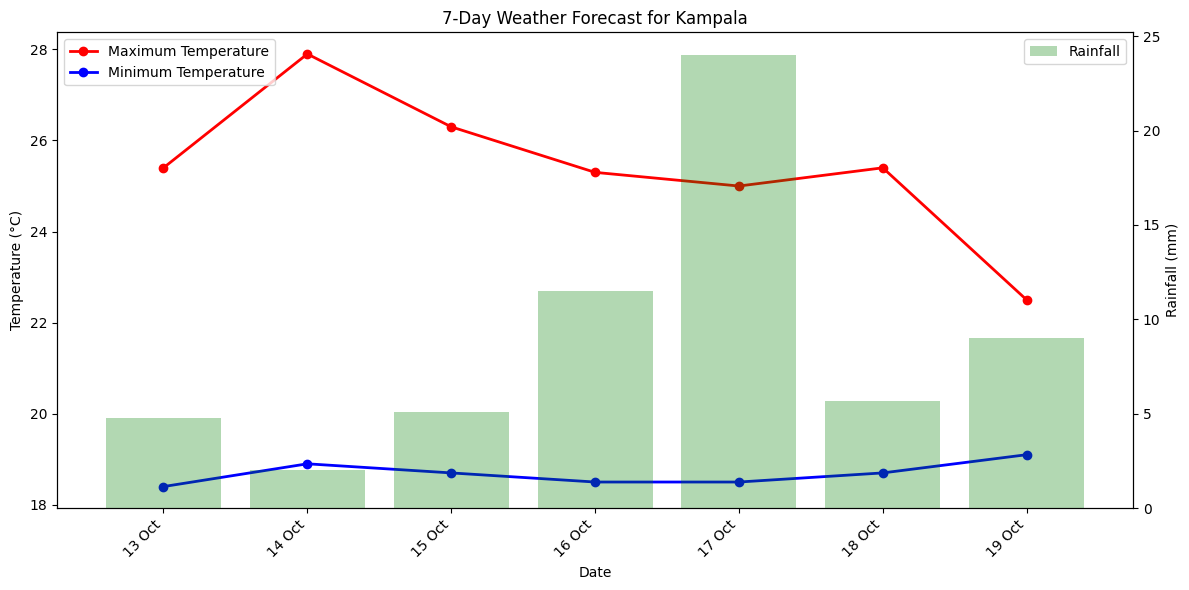

In [ ]:

# Plot temperatures and rainfall

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    weather_df["Date"],
    weather_df["Maximum Temperature (°C)"],
    color="red",
    marker="o",
    linewidth=2,
    label="Maximum Temperature"
)

ax1.plot(
    weather_df["Date"],
    weather_df["Minimum Temperature (°C)"],
    color="blue",
    marker="o",
    linewidth=2,
    label="Minimum Temperature"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")

ax2 = ax1.twinx()

ax2.bar(
    weather_df["Date"],
    weather_df["Rainfall (mm)"],
    color="green",
    alpha=0.3,
    label="Rainfall"
)

ax2.set_ylabel("Rainfall (mm)")

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

plt.title(f"{FORECAST_DAYS}-Day Weather Forecast for {CITY}")

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

fig.autofmt_xdate(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:

from unittest.mock import patch

# Test 1: Invalid city
print("TEST 1: Invalid City")

invalid_locations = geocode("XyzNonexistentCity12345")

assert invalid_locations == []
print("Invalid city handled successfully!")


# Test 2: Invalid latitude
print("\nTEST 2: Invalid Latitude")

try:
    get_forecast(200, 32.58219, 7)

except ValueError as error:
    print("Invalid latitude handled:", error)


# Test 3: Simulated network failure
print("\nTEST 3: Network Failure")

with patch(
    "requests.get",
    side_effect=requests.exceptions.ConnectionError(
        "Simulated network failure"
    )
), patch("time.sleep"):

    try:
        safe_request(
            "https://api.open-meteo.com/v1/forecast",
            max_retries=2
        )

    except WeatherAPIError as error:
        print("Network failure handled:", error)


# Test 4: Simulated tiny timeout
print("\nTEST 4: Tiny Timeout")

with patch(
    "requests.get",
    side_effect=requests.exceptions.Timeout(
        "Simulated timeout"
    )
), patch("time.sleep"):

    try:
        safe_request(
            "https://api.open-meteo.com/v1/forecast",
            timeout=0.000001,
            max_retries=2
        )

    except WeatherAPIError as error:
        print("Timeout handled:", error)

print("\nAll error-handling demonstrations completed!")


TEST 1: Invalid City
Invalid city handled successfully!

TEST 2: Invalid Latitude
Invalid latitude handled: Invalid latitude.

TEST 3: Network Failure
Attempt 1 failed. Retrying in 1 seconds...
Network failure handled: Request failed after 2 attempts: Simulated network failure

TEST 4: Tiny Timeout
Attempt 1 failed. Retrying in 1 seconds...
Timeout handled: Request failed after 2 attempts: Simulated timeout

All error-handling demonstrations completed!


In [ ]:

# MET Norway forecast

met_url = (
    "https://api.met.no/weatherapi/"
    "locationforecast/2.0/compact"
)



met_headers = {
    "User-Agent": f"StudentWeatherProject/1.0 ({MET_EMAIL})"
}

met_params = {
    "lat": round(latitude, 4),
    "lon": round(longitude, 4)
}

met_data = safe_request(
    met_url,
    params=met_params,
    headers=met_headers,
    timeout=15
)

timeseries = met_data["properties"]["timeseries"]

met_records = []

for item in timeseries:

    details = item["data"]["instant"]["details"]

    met_records.append({
        "Date and Time": item["time"],
        "Temperature (°C)": details.get(
            "air_temperature"
        ),
        "Wind Speed (m/s)": details.get(
            "wind_speed"
        )
    })

met_df = pd.DataFrame(met_records)

met_df["Date and Time"] = pd.to_datetime(
    met_df["Date and Time"],
    utc=True
).dt.tz_convert(forecast["timezone"])

print("MET Norway forecast retrieved successfully!")
print("Source: Norwegian Meteorological Institute")

display(met_df.head(10))


MET Norway forecast retrieved successfully!
Source: Norwegian Meteorological Institute


,Date and Time,Temperature (°C),Wind Speed (m/s)
0,2026-10-13 11:00:00+03:00,24.2,1.4
1,2026-10-13 12:00:00+03:00,25.4,2.1
2,2026-10-13 13:00:00+03:00,23.1,3.2
3,2026-10-13 14:00:00+03:00,21.7,4.1
4,2026-10-13 15:00:00+03:00,22.9,1.8
5,2026-10-13 16:00:00+03:00,23.4,1.3
6,2026-10-13 17:00:00+03:00,23.3,1.2
7,2026-10-13 18:00:00+03:00,22.9,2.0
8,2026-10-13 19:00:00+03:00,21.6,2.6
9,2026-10-13 20:00:00+03:00,20.9,3.3


In [ ]:

# MET Norway forecast

met_url = (
    "https://api.met.no/weatherapi/"
    "locationforecast/2.0/compact"
)

# Require genuine contact information
if not MET_EMAIL or MET_EMAIL == "your_actual_email@example.com":
    raise ValueError(
        "Configure your genuine contact email in Cell 3."
    )

met_headers = {
    "User-Agent": f"StudentWeatherProject/1.0 ({MET_EMAIL})"
}

met_params = {
    "lat": round(latitude, 4),
    "lon": round(longitude, 4)
}

met_data = safe_request(
    met_url,
    params=met_params,
    headers=met_headers,
    timeout=15
)

timeseries = met_data["properties"]["timeseries"]

met_records = []

for item in timeseries:

    details = item["data"]["instant"]["details"]

    met_records.append({
        "Date and Time": item["time"],
        "Temperature (°C)": details.get(
            "air_temperature"
        ),
        "Wind Speed (m/s)": details.get(
            "wind_speed"
        )
    })

met_df = pd.DataFrame(met_records)

met_df["Date and Time"] = pd.to_datetime(
    met_df["Date and Time"],
    utc=True
).dt.tz_convert(forecast["timezone"])

print("MET Norway forecast retrieved successfully!")
print("Source: Norwegian Meteorological Institute")

display(met_df.head(10))


MET Norway forecast retrieved successfully!
Source: Norwegian Meteorological Institute


,Date and Time,Temperature (°C),Wind Speed (m/s)
0,2026-10-13 11:00:00+03:00,24.2,1.4
1,2026-10-13 12:00:00+03:00,25.4,2.1
2,2026-10-13 13:00:00+03:00,23.1,3.2
3,2026-10-13 14:00:00+03:00,21.7,4.1
4,2026-10-13 15:00:00+03:00,22.9,1.8
5,2026-10-13 16:00:00+03:00,23.4,1.3
6,2026-10-13 17:00:00+03:00,23.3,1.2
7,2026-10-13 18:00:00+03:00,22.9,2.0
8,2026-10-13 19:00:00+03:00,21.6,2.6
9,2026-10-13 20:00:00+03:00,20.9,3.3


In [ ]:

# Prepare MET Norway daily data

met_df["Date"] = met_df["Date and Time"].dt.date

met_daily = met_df.groupby("Date").agg(
    MET_Max_Temp=("Temperature (°C)", "max"),
    MET_Min_Temp=("Temperature (°C)", "min")
).reset_index()

# Prepare Open-Meteo daily data

open_daily = weather_df[
    [
        "Date",
        "Maximum Temperature (°C)",
        "Minimum Temperature (°C)"
    ]
].copy()

open_daily["Date"] = open_daily["Date"].dt.date

# Merge the two sources

comparison = pd.merge(
    open_daily,
    met_daily,
    on="Date",
    how="inner"
)

# Calculate differences

comparison["Max Temp Difference (°C)"] = (
    comparison["Maximum Temperature (°C)"]
    - comparison["MET_Max_Temp"]
)

print("Open-Meteo versus MET Norway")
display(comparison)


Open-Meteo versus MET Norway


,Date,Maximum Temperature (°C),Minimum Temperature (°C),MET_Max_Temp,MET_Min_Temp,Max Temp Difference (°C)
0,2026-10-13,25.4,18.4,25.4,20.1,0.0
1,2026-10-14,27.9,18.9,27.6,19.1,0.3
2,2026-10-15,26.3,18.7,26.1,18.7,0.2
3,2026-10-16,25.3,18.5,24.2,20.0,1.1
4,2026-10-17,25.0,18.5,23.9,19.0,1.1
5,2026-10-18,25.4,18.7,23.0,19.3,2.4
6,2026-10-19,22.5,19.1,26.5,19.0,-4.0


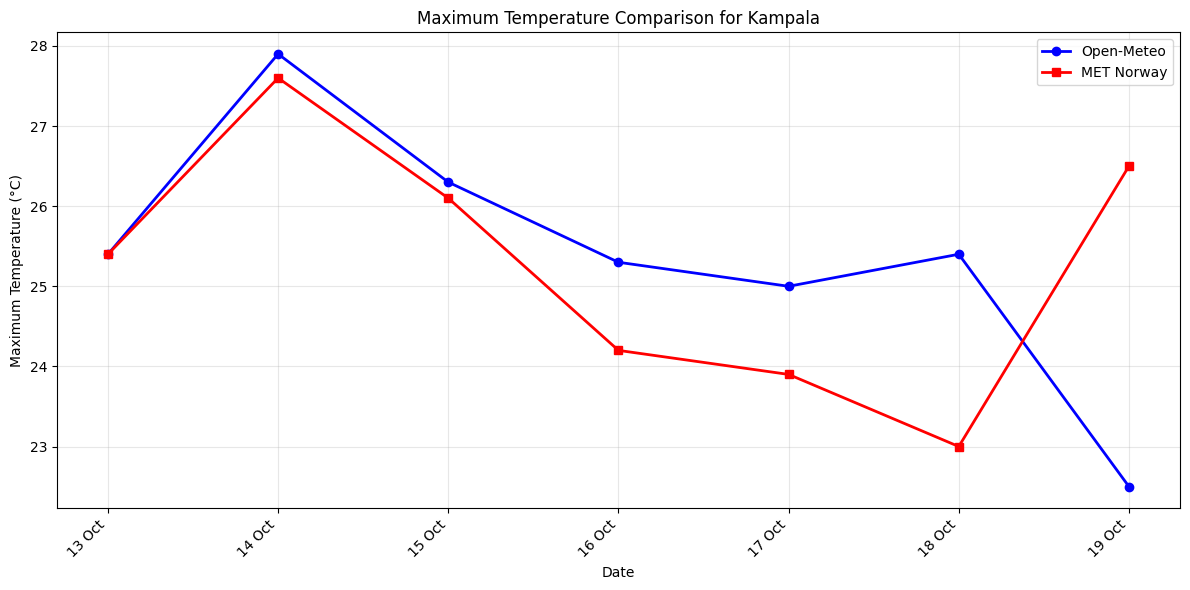

In [ ]:

# Compare maximum temperatures

dates = pd.to_datetime(comparison["Date"])

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    dates,
    comparison["Maximum Temperature (°C)"],
    marker="o",
    color="blue",
    linewidth=2,
    label="Open-Meteo"
)

ax.plot(
    dates,
    comparison["MET_Max_Temp"],
    marker="s",
    color="red",
    linewidth=2,
    label="MET Norway"
)

ax.set_title(
    f"Maximum Temperature Comparison for {CITY}"
)

ax.set_xlabel("Date")
ax.set_ylabel("Maximum Temperature (°C)")

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

ax.legend()
ax.grid(alpha=0.3)

fig.autofmt_xdate(rotation=45)

plt.tight_layout()
plt.show()


In [ ]:

# Run the five automated offline tests

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "tests/",
        "-v"
    ],
    cwd=repo_path,
    check=True
)

print("All GitHub tests completed successfully!")


All GitHub tests completed successfully!


# PART D: TECHNICAL REPORT

## 1. Introduction

Weather information plays an important role in planning daily activities, particularly in sectors such as agriculture, transport, construction and tourism. In Uganda, changes in rainfall and temperature can influence farming activities, travel arrangements and business operations. Access to weather forecasts can therefore support better planning and decision-making.

This project developed a Python-based weather forecasting application that retrieves weather information from publicly accessible Application Programming Interfaces (APIs). Kampala, Uganda, was selected as the main location for testing the application. The system uses Open-Meteo to identify geographical coordinates and retrieve daily forecasts, while MET Norway provides a second source of weather information for comparison.

The application was developed using Python libraries including `urllib`, `requests`, `pandas` and `matplotlib`. It demonstrates API communication, JSON processing, data visualisation, reusable functions, error handling and automated testing.

## 2. Data Flow and System Architecture

The application follows a sequence that begins with the user entering a city name and ends with the presentation of weather information.

### 2.1 Data Flow Diagram

```text
       USER INPUT
     (City: Kampala)
             |
             v
    Open-Meteo Geocoding API
             |
             v
    Latitude and Longitude
             |
       +-----+-----+
       |           |
       v           v
   Open-Meteo   MET Norway
   Forecast API Forecast API
       |           |
       v           v
   JSON Data    JSON Data
       |           |
       v           v
       Python Data Processing
             |
             v
       Pandas DataFrames
             |
       +-----+-----+
       |           |
       v           v
  Forecast Table  Charts
       |
       v
  Weather Summary
```

### 2.2 Description of the Data Flow

The first stage involves entering a city name, such as Kampala. The application sends the name to the Open-Meteo Geocoding API, which returns matching locations with their geographical coordinates. When several locations have the same name, the system displays available candidates and uses a configured selection number.

The second stage involves retrieving weather forecasts using the selected latitude and longitude. Open-Meteo provides daily maximum and minimum temperatures, precipitation totals, maximum wind speeds and numerical weather codes. MET Norway provides additional forecast information through its Locationforecast API.

Both APIs return information in JavaScript Object Notation (JSON), a structured format commonly used for exchanging information between applications. Python extracts the required variables and converts the results into pandas DataFrames.

The final stage involves displaying the information in tables and charts. Matplotlib is used to visualise maximum and minimum temperatures alongside precipitation. The application also calculates average temperatures, total forecast rainfall and the days with the highest temperature and precipitation.

This approach makes the application reusable because changing the configured city allows the same functions to retrieve forecasts for another location.

## 3. API Licensing and Usage Conditions

The project uses two weather information providers, each with specific conditions governing access and reuse.

### 3.1 Open-Meteo

Open-Meteo provides weather forecast and geocoding services through publicly accessible APIs. Its free API is intended for non-commercial use and is subject to limits of 10,000 requests per day, 5,000 per hour and 600 per minute. Weather data are made available under the Creative Commons Attribution 4.0 International (CC BY 4.0) licence, which requires appropriate acknowledgement of the source (Open-Meteo, n.d.).

For this academic project, the free API is appropriate because requests are limited to demonstration, testing and learning. However, if the application were developed into a commercial weather forecasting service, the developer would need to obtain suitable commercial API access.

The data licence and API access conditions must be considered separately. Although CC BY 4.0 permits commercial reuse of appropriately attributed data, the free hosted API is restricted to non-commercial purposes.

### 3.2 MET Norway

The Norwegian Meteorological Institute provides weather forecast data through its Locationforecast API. Its open data are generally licensed under the Norwegian Licence for Open Government Data (NLOD) 2.0 and Creative Commons Attribution 4.0, unless otherwise specified (MET Norway, n.d.-a).

Users are required to identify their applications through an appropriate User-Agent header containing genuine identification or contact information. They must also avoid excessive requests, respect caching requirements and acknowledge MET Norway as the data source.

The application therefore sends an identifying User-Agent with its MET Norway requests. It also uses HTTPS and limits requests to the information required for the project.

For a commercial product, these conditions would influence system design. The developer would need to implement caching, manage request frequency and ensure correct attribution. Compliance with the provider's terms would be necessary to avoid restricted access or service disruption.

## 4. Reliability Issues and Error Handling

One challenge when developing applications that depend on external APIs is that the service may not always respond as expected. Network interruptions, invalid user inputs, server errors and slow responses can affect application performance.

### 4.1 Invalid City Names and Geographical Coordinates

Users may enter locations that do not exist or names that match several places. The application addresses these situations through the `geocode()` function, which returns an empty list when no matching location is available and displays alternatives when multiple locations are returned.

The application also validates latitude and longitude values before requesting a forecast. Latitude must fall between -90 and +90 degrees, while longitude must fall between -180 and +180 degrees. Invalid values generate a meaningful error message instead of an unexplained failure.

### 4.2 Network Errors and Timeouts

Internet connectivity can be unreliable, and external servers may occasionally fail to respond. To address this problem, the application implements a `safe_request()` function that handles connection errors, timeouts and unsuccessful HTTP responses.

The function uses a timeout to prevent requests from waiting indefinitely. It also implements exponential backoff, where the application waits progressively longer before retrying a failed request. A maximum retry limit prevents repeated unsuccessful requests.

Custom exceptions provide clearer explanations when requests eventually fail. Permanent client errors are generally not retried, while temporary network and server failures may be retried.

### 4.3 Testing and Reproducibility

The project includes five automated tests using `pytest`. These verify city-name extraction, empty location results, missing JSON keys, weather-code interpretation and forecast-data parsing.

Saved sample JSON files allow these tests to execute without accessing the internet. The tests are stored in the GitHub repository alongside reusable Python modules, improving the organisation and reproducibility of the project.

The error-handling demonstrations also include simulated network failures and timeouts. These tests allow the application to demonstrate failure handling without deliberately disconnecting the computer.

Although these measures improve reliability, they cannot guarantee uninterrupted forecast retrieval because live requests remain dependent on external services and internet connectivity.

## 5. Privacy Implications of Location Queries

Weather forecasting applications require geographical information to identify the location for which weather predictions are requested. This introduces privacy considerations, especially where precise coordinates are used.

The application sends city names to Open-Meteo's geocoding service and geographical coordinates to weather forecast providers. Although this project uses Kampala as a general location, future applications could process more precise locations associated with individual users.

Such information may reveal where a person lives, works or travels. Open-Meteo's privacy terms explain that server logs may contain geographical coordinates and that operational data may be retained for troubleshooting and service purposes (Open-Meteo, n.d.).

MET Norway also explains that API requests may result in the storage of IP addresses and geographical coordinates in access logs (MET Norway, n.d.-b).

Developers should therefore minimise the information transmitted to external providers. For example, requesting a forecast for a city may be sufficient without collecting a user's exact GPS coordinates.

Users should also be informed when their location information is transmitted to third-party services. In a future commercial application, privacy protection could be strengthened through secure communication, limited retention of location information and the use of an application server to manage API requests.

The present project does not require user registration or a database of personal locations, reducing the amount of personal information handled by the application.

## 6. Conclusion

The project demonstrated how Python can integrate external web APIs to retrieve, process and visualise weather forecasts. Using Kampala as a case study, the application successfully organised weather information from Open-Meteo and MET Norway into tables and charts.

The project also demonstrated the importance of reliable programming practices, including input validation, timeout handling, automatic retries, reusable functions and offline testing.

An important lesson from the project is that accessing weather data is only one part of application development. Developers must also consider data quality, API licensing, privacy and system reliability.

Future improvements could include forecast caching, additional weather variables, evaluation against observed weather measurements and a simple web-based user interface.

## References

MET Norway. (n.d.-a). *Licensing and data policy*. https://docs.api.met.no/doc/License.html

MET Norway. (n.d.-b). *Terms of service*. https://api.met.no/doc/TermsOfService

MET Norway. (n.d.-c). *Locationforecast 2.0 documentation*. https://api.met.no/weatherapi/locationforecast/2.0/documentation

Open-Meteo. (n.d.). *Terms of use and privacy*. https://open-meteo.com/en/terms

Open-Meteo. (n.d.). *Weather forecast API documentation*. https://open-meteo.com/en/docs